In [3]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
import seaborn as sns


In [4]:
df = pd.read_csv("datasets/podatki_PM_a1.csv")
df.fillna(df.mean(), inplace=True)

# datum dropped manually

df.head()

,Glob_sevanje_mean,Hitrost_vetra_mean,Sunki_vetra_max,Padavine_sum,Vlaga_mean,Temperatura_Krvavec_mean,Temperatura_lokacija_mean,PM10,PM_vceraj,sinD,cosD
0,0.125,0.6750,2.9,0.0,79.1750,-2.9875,3.2000,44.3,51.4,0.034899,0.999391
1,0.375,0.7375,2.6,0.0,93.5625,-4.5250,2.8750,49.0,44.3,0.052336,0.998630
2,0.875,0.8875,3.2,0.0,93.3000,2.9625,0.6875,61.3,49.0,0.069756,0.997564
3,0.750,1.0000,4.5,0.0,94.2625,2.9875,0.5875,38.9,61.3,0.087156,0.996195
4,0.250,0.5750,2.3,0.0,87.6500,-0.2500,3.1625,30.3,38.9,0.104528,0.994522


In [5]:
# attributes (all columns except for target col)
x = df.loc[:, df.columns != 'PM10']
print(x)

# target variable
y = df['PM10'] 
print(y)


      Glob_sevanje_mean  Hitrost_vetra_mean  Sunki_vetra_max  Padavine_sum  \
0                 0.125              0.6750              2.9           0.0   
1                 0.375              0.7375              2.6           0.0   
2                 0.875              0.8875              3.2           0.0   
3                 0.750              1.0000              4.5           0.0   
4                 0.250              0.5750              2.3           0.0   
...                 ...                 ...              ...           ...   
1208              0.375              0.6125              2.6           0.0   
1209              0.375              0.7125              3.9           0.0   
1210              1.750              1.7000              5.4           0.0   
1211              0.500              1.0375              4.9           0.0   
1212              0.375              0.6000              1.7           0.0   

      Vlaga_mean  Temperatura_Krvavec_mean  Temperatura_lokacij

In [6]:
# 30-70 test-train
split = int(len(df) * 0.7) # to get index which is 70% of the dataset since rules of the assignment:
                                # "As the data is temporal do not perform random shuffle"

x_train, x_test = x[:split], x[split:]
y_train, y_test = y[:split], y[split:]


In [7]:
# with scikit learn
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
print("done")

done


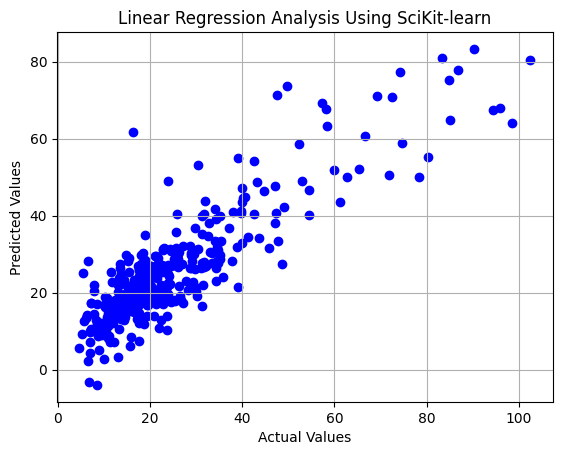

In [8]:
plt.scatter(y_test, y_pred, color='blue', label='Actual vs. Predicted')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression Analysis Using SciKit-learn")
plt.grid(True)
plt.show()


In [24]:
# add column of all 1s
x['Ones'] = 1

# redo spliting because of the new column
x_train_mine, x_test_mine = x[:split], x[split:]
y_train_mine, y_test_mine = y[:split], y[split:]

In [25]:
# Without library

# calculates beta from y_pred = x * beta formula
def calculateBeta(x, y):   
    xtx_inv = np.linalg.inv(np.dot(x.T, x))  # (X^T X)^(-1)
    xty = np.dot(x.T, y)  # X^T y
    beta = np.dot(xtx_inv, xty)  # (X^T X)^(-1) X^T y
    return beta


In [26]:
# Calculate beta using training data
beta = calculateBeta(x_train_mine, y_train_mine)

# Predict using the training set and test set
y_train_pred_mine = np.dot(x_train_mine, beta)
y_test_pred_mine = np.dot(x_test_mine, beta)


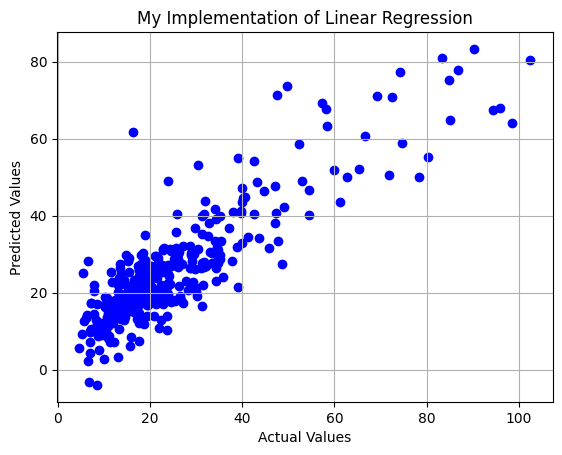

In [27]:
plt.scatter(y_test, y_test_pred_mine, color='blue', label='Actual vs. Predicted')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("My Implementation of Linear Regression")
plt.grid(True)
plt.show()


In [28]:
mae_scikit = mean_absolute_error(y_test, y_pred)
mae_mine = mean_absolute_error(y_test_mine, y_test_pred_mine)

print(f"MAE Scikit: {mae_scikit}")
print(f"MAE with my implementation: {mae_mine}")

MAE Scikit: 6.041491247227988
MAE with my implementation: 6.041491247228126


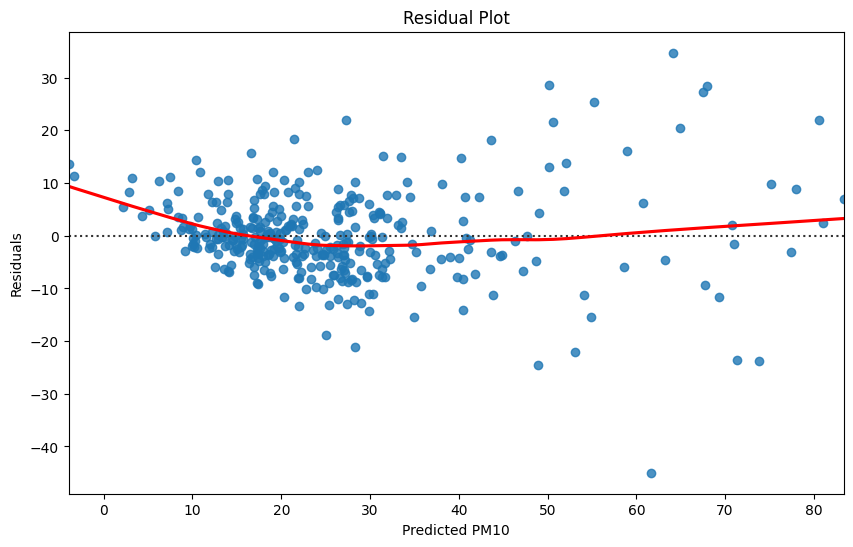

In [34]:
# Residual plot 
plt.figure(figsize=(10, 6))
sns.residplot(x=y_test_pred_mine, y=(y_test_mine - y_test_pred_mine), lowess=True, line_kws={'color': 'red'})
plt.xlabel("Predicted PM10")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


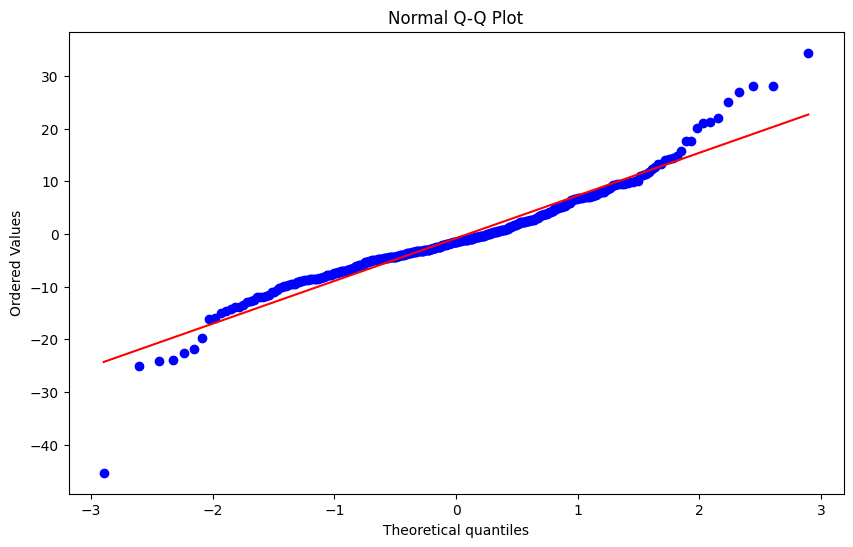

In [33]:
# Q-Q plot for residuals
from scipy import stats
residuals = y_test_mine - y_test_pred_mine
plt.figure(figsize=(10, 6))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Normal Q-Q Plot")
plt.show()


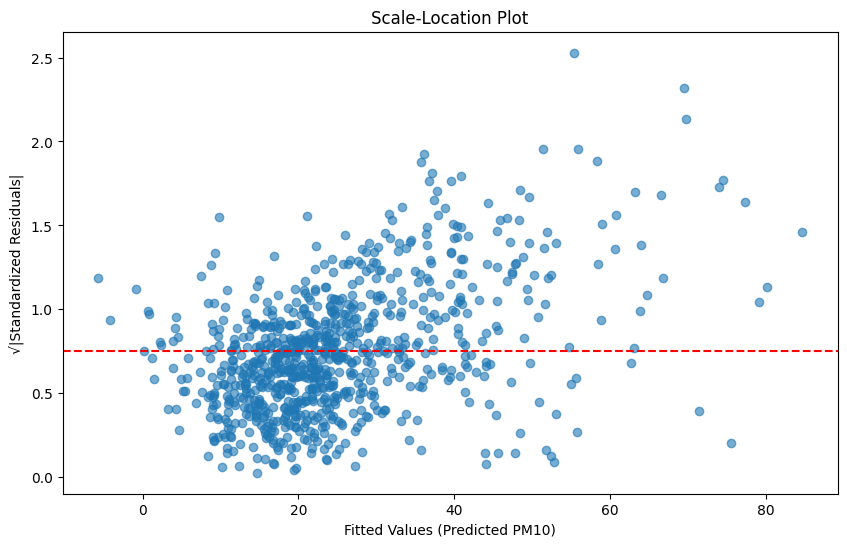

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Standardize residuals by dividing by their standard deviation
# Using training set residuals for illustration
residuals_train = y_train_mine - y_train_pred_mine
standardized_residuals = residuals_train / np.std(residuals_train)

# Calculate the square root of the absolute standardized residuals
sqrt_abs_standardized_residuals = np.sqrt(np.abs(standardized_residuals))

# Plot Scale-Location plot
plt.figure(figsize=(10, 6))
plt.scatter(y_train_pred_mine, sqrt_abs_standardized_residuals, alpha=0.6)
plt.axhline(y=np.mean(sqrt_abs_standardized_residuals), color='red', linestyle='--')
plt.xlabel("Fitted Values (Predicted PM10)")
plt.ylabel("√|Standardized Residuals|")
plt.title("Scale-Location Plot")
plt.show()
